part1

In [1]:
import pandas as pd

housing_df = pd.read_csv('data/Melbourne house sales for A2.csv')
housing_df.head()

,Suburb,Address,Rooms,Type,Price,Method,SellerG,Date,Postcode,Bedroom2,Bathroom,Car,Landsize,BuildingArea,YearBuilt,CouncilArea,Latitude,Longitude
0,Abbotsford,85 Turner St,2,h,1480000,S,Biggin,3/12/2016,3067,2,1,1.0,202,NaN,NaN,Yarra,-37.7996,144.9984
1,Abbotsford,25 Bloomburg St,2,h,1035000,S,Biggin,4/02/2016,3067,2,1,0.0,156,79.0,1900.0,Yarra,-37.8079,144.9934
2,Abbotsford,5 Charles St,3,h,1465000,SP,Biggin,4/03/2017,3067,3,2,0.0,134,150.0,1900.0,Yarra,-37.8093,144.9944
3,Abbotsford,40 Federation La,3,h,850000,PI,Biggin,4/03/2017,3067,3,2,1.0,94,NaN,NaN,Yarra,-37.7969,144.9969
4,Abbotsford,55a Park St,4,h,1600000,VB,Nelson,4/06/2016,3067,3,1,2.0,120,142.0,2014.0,Yarra,-37.8072,144.9941


In [2]:
num_rows = housing_df.shape[0]
num_cols = housing_df.shape[1]
brunswick_count = housing_df[housing_df['Suburb'] == 'Brunswick'].shape[0]
suburb_counts = housing_df['Suburb'].value_counts()
top_suburb = suburb_counts.index[0]
top_count = suburb_counts.iloc[0]
print(f'The Melbourne house sales data has {num_rows} rows and {num_cols} fields.')
print(f'In this dataset, the suburb of Brunswick is frequently represented ({brunswick_count} houses sold), but the suburb with the most sales is {top_suburb} ({top_count} houses sold).')

The Melbourne house sales data has 13580 rows and 18 fields.
In this dataset, the suburb of Brunswick is frequently represented (222 houses sold), but the suburb with the most sales is Reservoir (359 houses sold).


In [60]:
print(housing_df.columns.tolist())


land_col = 'Landsize'
price_col = 'Price'
land_clean = housing_df[land_col].dropna()
price_clean = housing_df[price_col]


land_mean = land_clean.mean()
land_std = land_clean.std()
land_median = land_clean.median()
land_min = land_clean.min()
land_max = land_clean.max()

price_mean = price_clean.mean()
price_std = price_clean.std()
price_median = price_clean.median()
price_min = price_clean.min()
price_max = price_clean.max()


print("\nLand Size:")
print(f"  Mean:     {land_mean:,.1f} m²")
print(f"  Std Dev:  {land_std:,.1f} m²")
print(f"  Median:   {land_median:,.1f} m²")
print(f"  Minimum:  {land_min:,.1f} m²")
print(f"  Maximum:  {land_max:,.1f} m²")

print("\nSale Price:")
print(f"  Mean:     ${price_mean:,.0f}")
print(f"  Std Dev:  ${price_std:,.0f}")
print(f"  Median:   ${price_median:,.0f}")
print(f"  Minimum:  ${price_min:,.0f}")
print(f"  Maximum:  ${price_max:,.0f}")

['Suburb', 'Address', 'Rooms', 'Type', 'Price', 'Method', 'SellerG', 'Date', 'Postcode', 'Bedroom2', 'Bathroom', 'Car', 'Landsize', 'BuildingArea', 'YearBuilt', 'CouncilArea', 'Latitude', 'Longitude']

Land Size:
  Mean:     558.4 m²
  Std Dev:  3,990.7 m²
  Median:   440.0 m²
  Minimum:  0.0 m²
  Maximum:  433,014.0 m²

Sale Price:
  Mean:     $1,075,684
  Std Dev:  $639,311
  Median:   $903,000
  Minimum:  $85,000
  Maximum:  $9,000,000


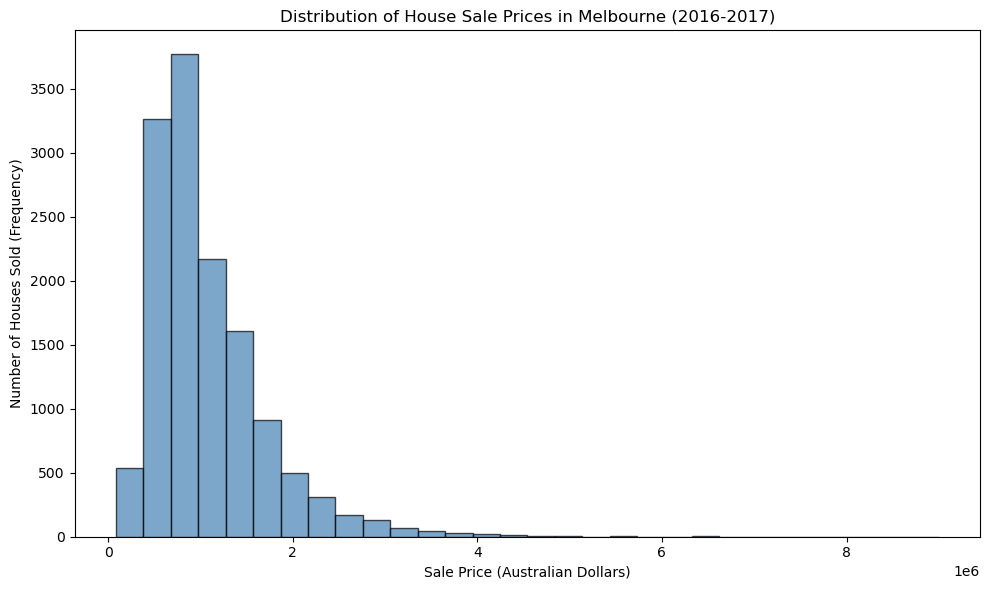

In [62]:
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 6))
plt.hist(housing_df['Price'], bins=30, edgecolor='black', alpha=0.7, color='steelblue')
plt.title('Distribution of House Sale Prices in Melbourne (2016-2017)')
plt.xlabel('Sale Price (Australian Dollars)')
plt.ylabel('Number of Houses Sold (Frequency)')
plt.tight_layout()
plt.show()

The histogram shows a right-skewed distribution rather than a standard normal distribution. It can be distanceerved from the data that the mean is higher than the median, and the right tail of the histogram is significantly longer, indicating that there're some extremely expensive houses as outliers.create a long right tail.


part2

In [5]:
import geopandas as gpd
housing_df = pd.read_csv('data/Melbourne house sales for A2.csv')
pt_geoms = gpd.points_from_xy(
    x=housing_df['Longitude'], 
    y=housing_df['Latitude'], 
    crs='EPSG:4326'
)

housing_gdf = gpd.GeoDataFrame(housing_df, geometry=pt_geoms)

flinders_geom = gpd.points_from_xy(x=[144.9671], y=[-37.8182], crs='EPSG:4326')
flinders = flinders_geom[0] 

housing_gdf['distance_degrees'] = housing_gdf.distance(flinders)

print("Distance (in degrees) of the first 5 house:：")
print(housing_gdf[['Suburb', 'Price', 'distance_degrees']].head())

housing_gdf['distance_km_approx'] = housing_gdf['distance_degrees'] * 111

print("Approximate distance (in kilometers) of the first 5 houses:")
print(housing_gdf[['Suburb', 'Price', 'distance_km_approx']].head())

Distance (in degrees) of the first 5 house:：
       Suburb    Price  distance_degrees
0  Abbotsford  1480000          0.036409
1  Abbotsford  1035000          0.028245
2  Abbotsford  1465000          0.028714
3  Abbotsford   850000          0.036630
4  Abbotsford  1600000          0.029155
Approximate distance (in kilometers) of the first 5 houses:
       Suburb    Price  distance_km_approx
0  Abbotsford  1480000            4.041452
1  Abbotsford  1035000            3.135195
2  Abbotsford  1465000            3.187266
3  Abbotsford   850000            4.065889
4  Abbotsford  1600000            3.236178


C:\Users\Leohard\AppData\Local\Temp\ipykernel_28404\254707411.py:14: UserWarning: Geometry is in a geographic CRS. Results from 'distance' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  housing_gdf['distance_degrees'] = housing_gdf.distance(flinders)


No
The current CRS is WGS84 (EPSG:4326), which is a geographic coordinate system with units in decimal degrees, not meters or kilometers. By the way, the distance() method computes planar Euclidean distances, but the Earth is spherical, which introduces errors.



In [6]:
housing_gdf_proj = housing_gdf.to_crs('EPSG:7855')

flinders_wgs84 = gpd.points_from_xy(x=[144.9671], y=[-37.8182], crs='EPSG:4326')
flinders_proj = flinders_wgs84.to_crs('EPSG:7855')[0]

housing_gdf_proj['distance_meters'] = housing_gdf_proj.distance(flinders_proj)
housing_gdf_proj['distance_km'] = housing_gdf_proj['distance_meters'] / 1000

print("\n Distance of the First 5 houses:")
print(housing_gdf_proj[['Suburb', 'Price', 'distance_meters', 'distance_km']].head(5))



 Distance of the First 5 houses:
       Suburb    Price  distance_meters  distance_km
0  Abbotsford  1480000      3443.660857     3.443661
1  Abbotsford  1035000      2582.627934     2.582628
2  Abbotsford  1465000      2598.904458     2.598904
3  Abbotsford   850000      3532.068532     3.532069
4  Abbotsford  1600000      2672.635533     2.672636


In [7]:
bins = [0, 5, 10, 15, 20, 25, 30, float('inf')]
labels = ['0-5 km', '5-10 km', '10-15 km', '15-20 km', '20-25 km', '25-30 km', '30+ km']

housing_gdf_proj['distance_band'] = pd.cut(
    housing_gdf_proj['distance_km'], 
    bins=bins, 
    labels=labels, 
    right=False
)

mean_price_by_band = housing_gdf_proj.groupby('distance_band', observed=True)['Price'].mean()
count_by_band = housing_gdf_proj.groupby('distance_band', observed=True)['Price'].count()

results_df = pd.DataFrame({
    'Distance(km)': labels,
    'Number of Houses': count_by_band.values,
    'Mean Price': mean_price_by_band.values.round(0).astype(int)
})
print(results_df.to_string(index=False))

Distance(km)  Number of Houses  Mean Price
      0-5 km              2024     1130970
     5-10 km              4518     1163600
    10-15 km              4630     1073657
    15-20 km              1243      958168
    20-25 km               544      879528
    25-30 km               342      722725
      30+ km               279      623259


The mean price of house is negatively correlated with distance from Flinders Street Station.

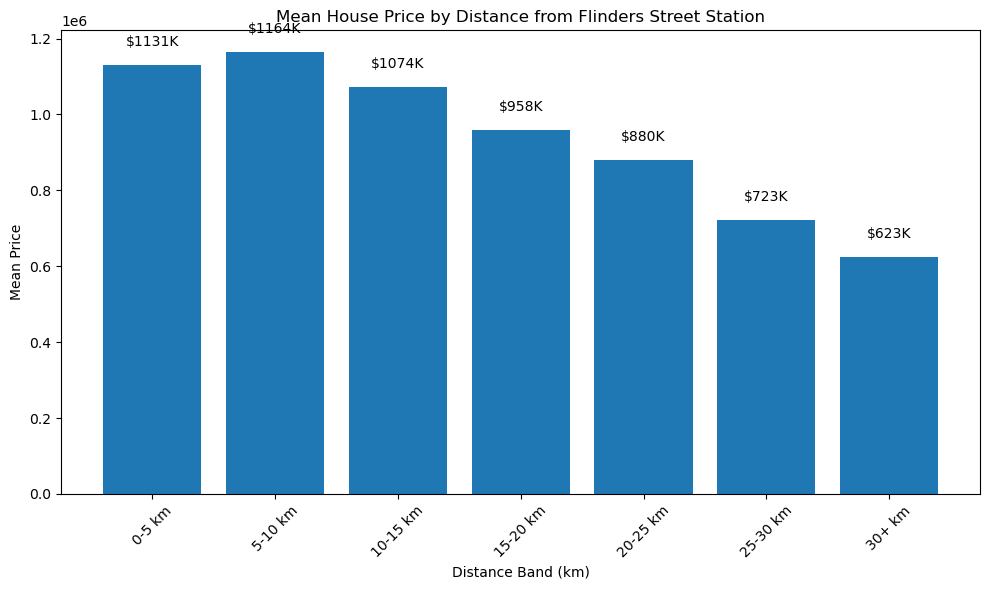

In [8]:
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 6))

bars = plt.bar(results_df['Distance(km)'], results_df['Mean Price'], )

plt.title('Mean House Price by Distance from Flinders Street Station')
plt.xlabel('Distance Band (km)')
plt.ylabel('Mean Price')
plt.xticks(rotation=45)

for bar, price in zip(bars, results_df['Mean Price']):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 50000,
             f'${price/1000:.0f}K', ha='center')

plt.tight_layout()
plt.show()

Part 3

In [9]:
census_file = 'data/Census 2021 table G02 Victoria.gpkg'

census_gdf = gpd.read_file(census_file)

print(f"\nNumber of rows: {census_gdf.shape[0]}")
print(f"Number of columns: {census_gdf.shape[1]}")

print(f"\nColumn names:\n{census_gdf.columns.tolist()}")

print("\nFirst 5 rows:")
print(census_gdf.head())

print(f"\nCRS: {census_gdf.crs}")



Number of rows: 2946
Number of columns: 13

Column names:
['id', 'SAL_CODE_2021', 'SAL_NAME_2021', 'Median_age_persons', 'Median_mortgage_repay_monthly', 'Median_tot_prsnl_inc_weekly', 'Median_rent_weekly', 'Median_tot_fam_inc_weekly', 'Average_num_psns_per_bedroom', 'Median_tot_hhd_inc_weekly', 'Average_household_size', 'AREA_ALBERS_SQKM', 'geometry']

First 5 rows:
   id SAL_CODE_2021      SAL_NAME_2021  Median_age_persons  \
0   1      SAL20001           Abbeyard                63.0   
1   2      SAL20002  Abbotsford (Vic.)                33.0   
2   3      SAL20003         Aberfeldie                41.0   
3   4      SAL20004          Aberfeldy                46.0   
4   5      SAL20005            Acheron                56.0   

   Median_mortgage_repay_monthly  Median_tot_prsnl_inc_weekly  \
0                            0.0                       2250.0   
1                         2167.0                       1354.0   
2                         2600.0                       1053.0

In [10]:
housing_df = pd.read_csv('data/Melbourne house sales for A2.csv')
housing_gdf = gpd.GeoDataFrame(
    housing_df,
    geometry=gpd.points_from_xy(housing_df['Longitude'], housing_df['Latitude']),
    crs='EPSG:4326'
).to_crs('EPSG:7855')

census_gdf = gpd.read_file('data/Census 2021 table G02 Victoria.gpkg').to_crs('EPSG:7855')

housing_with_census = gpd.sjoin(
    housing_gdf, 
    census_gdf, 
    how='left', 
    predicate='within'
)

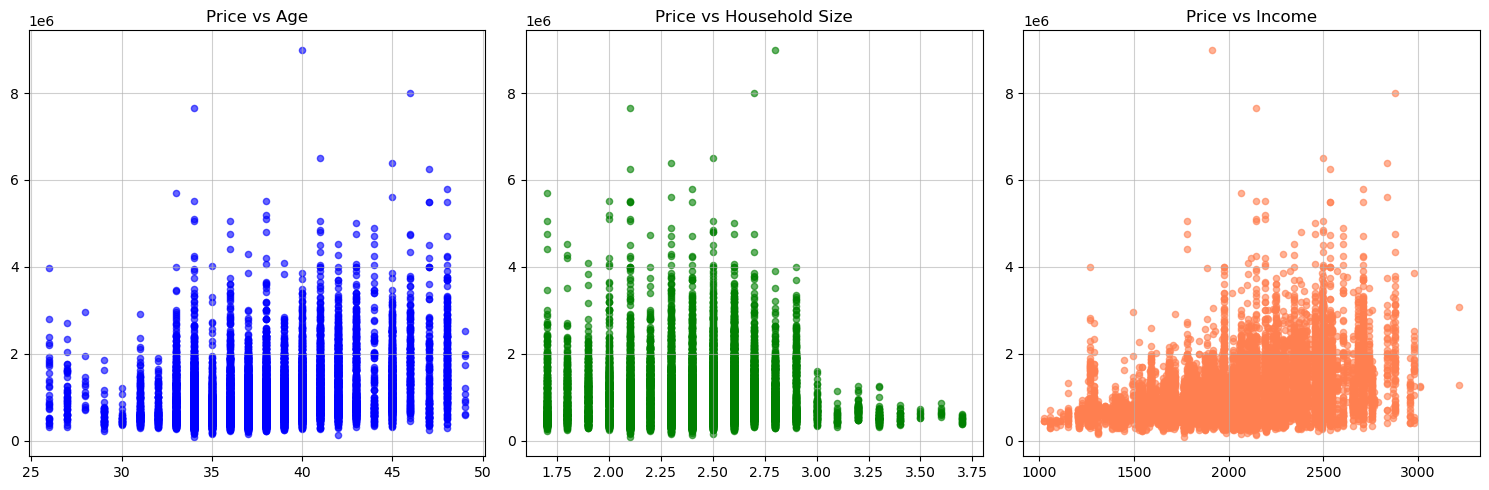

In [66]:
import matplotlib.pyplot as plt

median_age = 'Median_age_persons'
hh_size = 'Average_household_size'
income = 'Median_tot_hhd_inc_weekly'
plot_data = housing_with_census.dropna(subset=['Price', median_age, hh_size, income])

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].scatter(plot_data[median_age], plot_data['Price'], alpha=0.6, s=20, c='blue')
axes[0].set_title('Price vs Age')
axes[0].grid(True, alpha=0.6)

axes[1].scatter(plot_data[hh_size], plot_data['Price'], alpha=0.6, s=20, c='green')
axes[1].set_title('Price vs Household Size')
axes[1].grid(True, alpha=0.6)

axes[2].scatter(plot_data[income], plot_data['Price'], alpha=0.6, s=20, c='coral')
axes[2].set_title('Price vs Income')
axes[2].grid(True, alpha=0.6)

plt.tight_layout()
plt.show()

In [12]:
r_age = plot_data['Price'].corr(plot_data[median_age])
r_hh = plot_data['Price'].corr(plot_data[hh_size])
r_income = plot_data['Price'].corr(plot_data[income])


print(f"Price vs Age:         r = {r_age:.4f}")
print(f"Price vs Household Size:     r = {r_hh:.4f}")
print(f"Price vs Income:         r = {r_income:.4f}")

Price vs Age:         r = 0.3108
Price vs Household Size:     r = -0.0128
Price vs Income:         r = 0.4019


Household income (r = 0.4019):Strongest correlation with house prices. Higher-income individuals tend to buy more expensive houses.
Median age (r = 0.3108):Moderate positive correlation. Increasing age is often associated with greater income.
Household size (r ≈ 0):No explanatory power. The price level of a house purchase is unrelated to household size.

(a)：In order to analyse the relationships between house prices and age, household size, and income, it is necessary to link the attributes of the Census data with the house sales data. Furthermore, the join operation help us understand the factors that influence house prices.
(b)：Spatial join uses real location as the boundary criterion, avoiding errors caused by incomplete name matching and ambiguous boundary areas.

part4

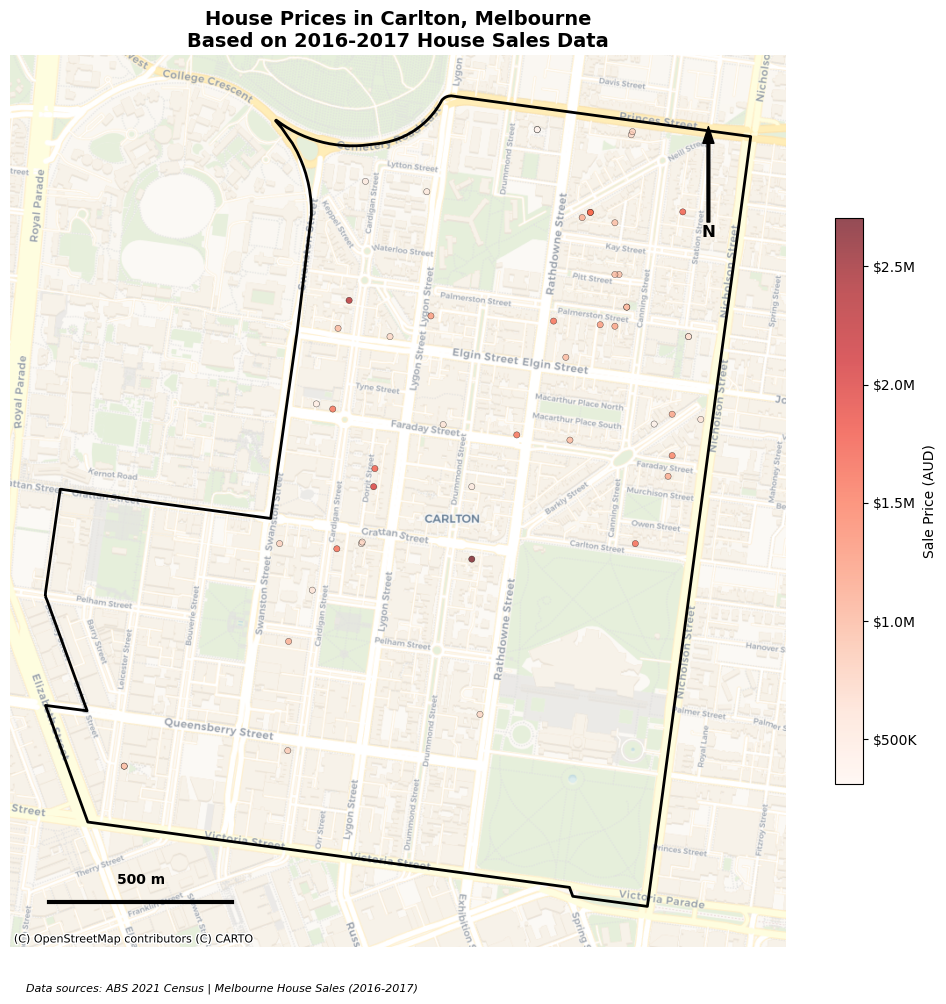

In [22]:

import contextily as ctx

housing_df = pd.read_csv('data/Melbourne house sales for A2.csv')
housing_gdf = gpd.GeoDataFrame(
    housing_df,
    geometry=gpd.points_from_xy(housing_df.Longitude, housing_df.Latitude),
    crs='EPSG:4326'
)

census_gdf = gpd.read_file('data/Census 2021 table G02 Victoria.gpkg')
carlton = census_gdf[census_gdf['SAL_NAME_2021'] == 'Carlton (Vic.)'].to_crs('EPSG:3857')

housing_web = housing_gdf.to_crs('EPSG:3857')
houses = gpd.sjoin(housing_web, carlton, predicate='within')

fig, ax = plt.subplots(figsize=(10, 10))

carlton.boundary.plot(ax=ax, edgecolor='black', linewidth=2)

scatter = ax.scatter(houses.geometry.x, houses.geometry.y, 
                     c=houses['Price'], cmap='Reds', s=20, alpha=0.7, 
                     edgecolors='black', linewidth=0.3)

ctx.add_basemap(ax, crs=houses.crs, source=ctx.providers.CartoDB.Voyager, alpha=0.8)

ax.set_title('House Prices in Carlton, Melbourne\nBased on 2016-2017 House Sales Data', 
             fontsize=14, fontweight='bold')

x_min, x_max = ax.get_xlim()
y_min, y_max = ax.get_ylim()
arrow_x = x_max - (x_max - x_min) * 0.1
arrow_y = y_max - (y_max - y_min) * 0.08
ax.annotate('N', xy=(arrow_x, arrow_y), xytext=(arrow_x, arrow_y - 300),
            arrowprops=dict(facecolor='black', width=2, headwidth=8),
            fontsize=12, fontweight='bold', ha='center')

scale_length_m = 500
x_center = x_min + (x_max - x_min) * 0.05
y_scale = y_min + (y_max - y_min) * 0.05
ax.plot([x_center, x_center + scale_length_m], [y_scale, y_scale], 
        color='black', linewidth=3)
ax.text(x_center + scale_length_m/2, y_scale + 50, '500 m', 
        ha='center', fontsize=10, fontweight='bold')

cbar = plt.colorbar(scatter, ax=ax, shrink=0.6, pad=0.05)
cbar.set_label('Sale Price (AUD)', fontsize=10)
cbar.formatter = FuncFormatter(currency_formatter)
cbar.update_ticks()

ax.text(x_min + (x_max - x_min) * 0.02, y_min - (y_max - y_min) * 0.05,
        'Data sources: ABS 2021 Census | Melbourne House Sales (2016-2017)',
        fontsize=8, ha='left', style='italic')

ax.set_axis_off()

plt.tight_layout()
plt.show()

Part 5

In [14]:
housing_df = pd.read_csv('data/Melbourne house sales for A2.csv')
housing = gpd.GeoDataFrame(
    housing_df,
    geometry=gpd.points_from_xy(housing_df.Longitude, housing_df.Latitude),
    crs='EPSG:4326'
).to_crs('EPSG:7855')

census = gpd.read_file('data/Census 2021 table G02 Victoria.gpkg').to_crs('EPSG:7855')

def calc_ann(coords, area):
    n = len(coords)
    min_dists = []
    for i in range(n):
        dists = np.sqrt(((coords - coords[i])**2).sum(axis=1))
        min_dists.append(dists[dists > 0].min())
    distance = np.mean(min_dists)
    exp = 1 / (2 * np.sqrt(n / area))
    z = (distance - exp) / (0.26136 / np.sqrt(n**2 / area))
    return distance, z

for name, search in [('Carlton', 'Carlton'), ('Doncaster East', 'Doncaster East'), ('Keilor East', 'Keilor East')]:
    boundary = census[census['SAL_NAME_2021'].str.contains(search, na=False)].dissolve()
    houses = gpd.sjoin(housing, boundary, predicate='within')
    coords = np.array([[p.x, p.y] for p in houses.geometry])
    distance, z = calc_ann(coords, boundary.geometry.iloc[0].area)
    print(f"{name}: distance={distance:.1f}m, z={z:.2f}")

Carlton: distance=87.7m, z=-1.71
Doncaster East: distance=260.5m, z=0.32
Keilor East: distance=100.6m, z=-5.66


In [15]:
import numpy as np
from scipy import stats

z_scores = {
    'Carlton': -1.71,
    'Doncaster East': 0.32,
    'Keilor East': -5.66
}

for area, z in z_scores.items():
    p_value = 2 * stats.norm.cdf(-abs(z))
    
    print(f" {area}")
    print(f" p-value: {p_value:.6f}")


 Carlton
 p-value: 0.087266
 Doncaster East
 p-value: 0.748968
 Keilor East
 p-value: 0.000000


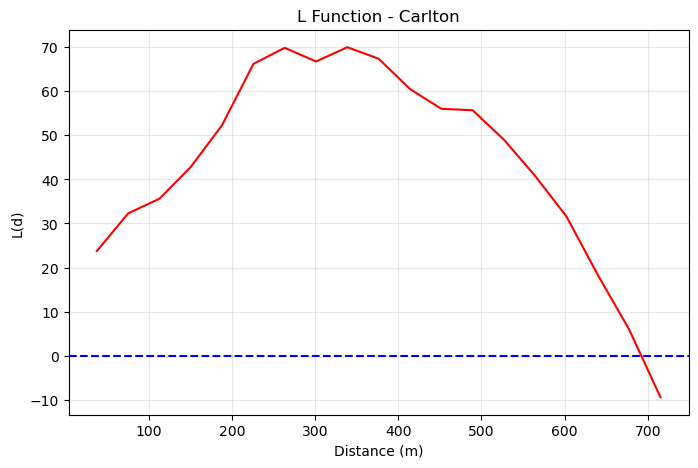

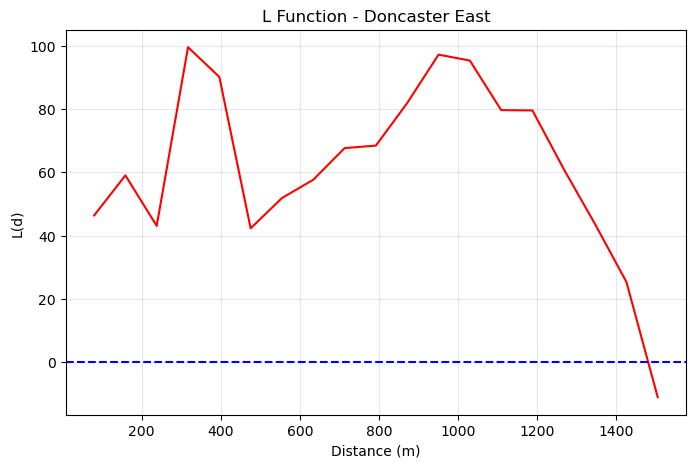

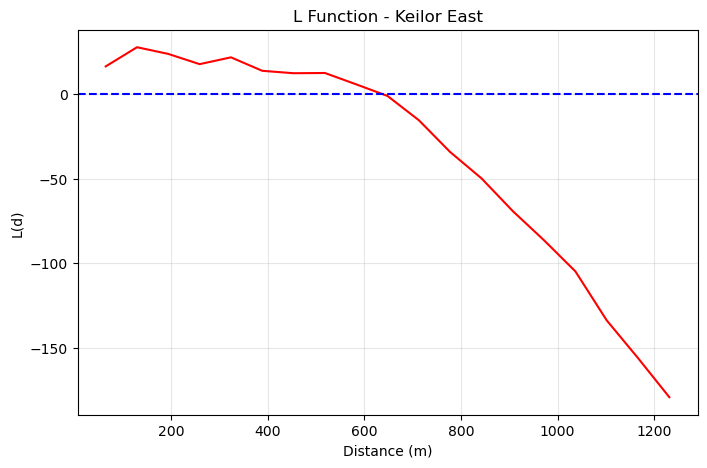

In [16]:
def l_func(coords, d):
    n = len(coords)
    area = (np.ptp(coords[:,0]) * np.ptp(coords[:,1]))  # 使用 np.ptp() 替代 .ptp()
    count = 0
    for i in range(n):
        for j in range(n):
            if i != j:
                dist = np.hypot(coords[i,0]-coords[j,0], coords[i,1]-coords[j,1])
                if dist < d:
                    count += 1
    k = (count * area) / (n * n)
    return np.sqrt(k / np.pi) - d

for name, search in [('Carlton', 'Carlton'), ('Doncaster East', 'Doncaster East'), ('Keilor East', 'Keilor East')]:
    boundary = census[census['SAL_NAME_2021'].str.contains(search, na=False)].dissolve()
    houses = gpd.sjoin(housing, boundary, predicate='within')
    coords = np.array([[p.x, p.y] for p in houses.geometry])
    
    max_d = min(np.ptp(coords[:,0]), np.ptp(coords[:,1])) / 2  
    dists = np.linspace(0, max_d, 20)[1:]
    l_vals = [l_func(coords, d) for d in dists]
    
    plt.figure(figsize=(8,5))
    plt.plot(dists, l_vals, 'r-')
    plt.axhline(y=0, color='b', linestyle='--')
    plt.xlabel('Distance (m)')
    plt.ylabel('L(d)')
    plt.title(f'L Function - {name}')
    plt.grid(alpha=0.3)
    plt.show()

(a): Carlton shows a non-significant clustering trend (p = 0.087), Doncaster East exhibits a random distribution (p = 0.749), while Keilor East displays a highly significant clustering pattern (p < 0.001). However, we can't know the reason of these difference.
(b): ANN is quick but only has single-scale assessment of point patterns, however L function offers multi-scale insights but is sensitive to edge effects. P-value is critical to correctly interpret clustering results.

When calculating the K function, we need to draw a circle for each point to count the number of points within that circle. However, to points located in the boundary of the study area, the circle will lie outside the area, which leads to inaccurate counts.
To solve the problem, we can set lower weights to points in boundary area to low down the effect. 



part6

In [17]:
import geopandas as gpd
census_gdf = gpd.read_file('data/Census 2021 table G02 Victoria.gpkg')
melbourne_boundary = gpd.read_file('data/Greater Melbourne (ABS) study area.shp')

melbourne_census = gpd.clip(census_gdf, melbourne_boundary)

print(f"Origin: {len(census_gdf)} ")
print(f"After Census: {len(melbourne_census)} ")

Origin: 2946 
After Census: 577 


We pick 'Median_tot_hhd_inc_weekly'

In [18]:
selected_attribute = 'Median_tot_hhd_inc_weekly'  
attribute_label = 'Median Weekly Household Income'

melbourne_clean = melbourne_census.dropna(subset=[selected_attribute])

print(f"Attribute: {attribute_label}")
print(f"Range: ${melbourne_clean[selected_attribute].min():.0f} - ${melbourne_clean[selected_attribute].max():.0f}")
print(f"Average: ${melbourne_clean[selected_attribute].mean():.0f}")
print(f"Standard Deviation: ${melbourne_clean[selected_attribute].std():.0f}")

Attribute: Median Weekly Household Income
Range: $0 - $4750
Average: $1960
Standard Deviation: $501


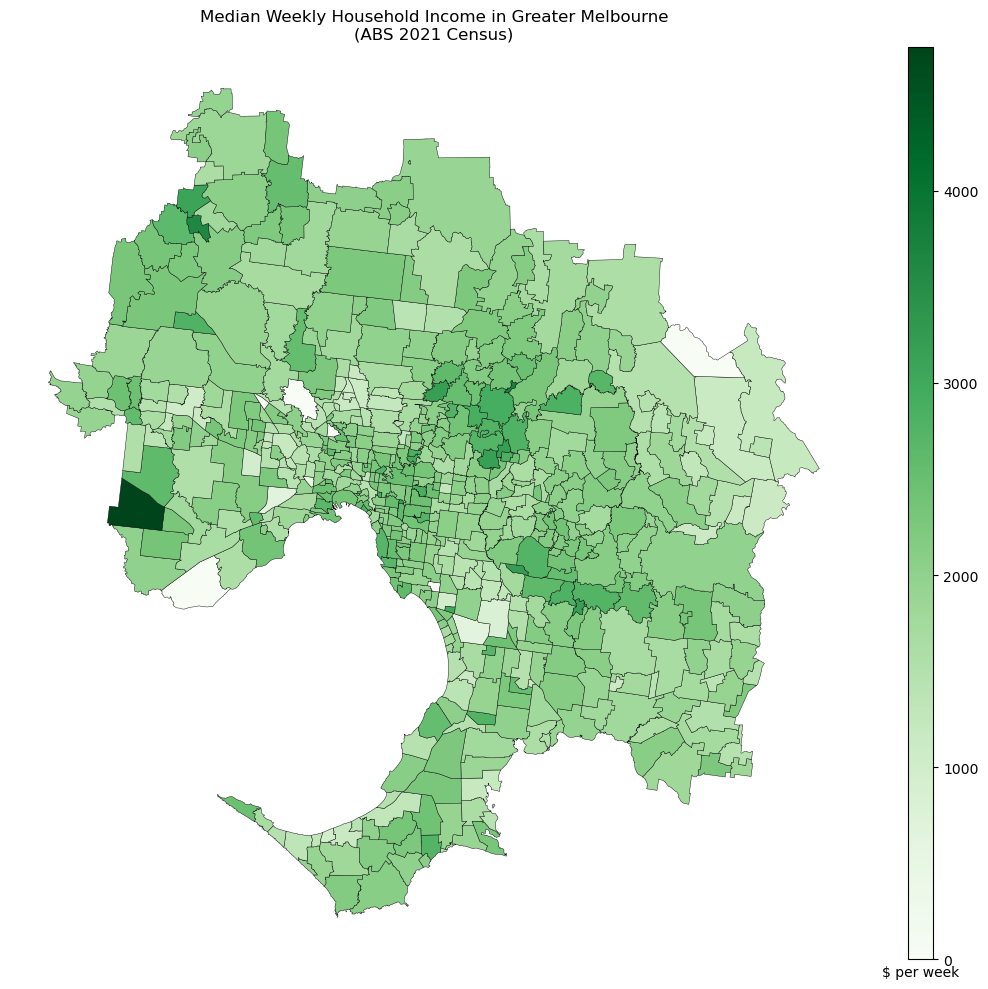

In [25]:
fig, ax = plt.subplots(1, 1, figsize=(12, 10))

divider = make_axes_locatable(ax)
cax = divider.append_axes("right", size="3%", pad=0.5)

melbourne_clean.plot(
    column=selected_attribute,
    cmap='Greens',
    edgecolor='black',
    linewidth=0.3,
    ax=ax,
    legend=True,
    cax=cax
)

ax.set_title("Median Weekly Household Income in Greater Melbourne\n(ABS 2021 Census)", fontsize=12)
cax.set_xlabel('$ per week', loc='center', fontsize=10)

ax.set_axis_off()

plt.tight_layout()
plt.show()

In [67]:
from pysal.lib import weights
from pysal.explore import esda

w = weights.KNN.from_dataframe(melbourne_clean, k=5)
w.transform = 'R'
moran = esda.moran.Moran(melbourne_clean['Median_tot_hhd_inc_weekly'].values, w)

print(f"Moran's I: {moran.I:.4f}")

Moran's I: 0.3264


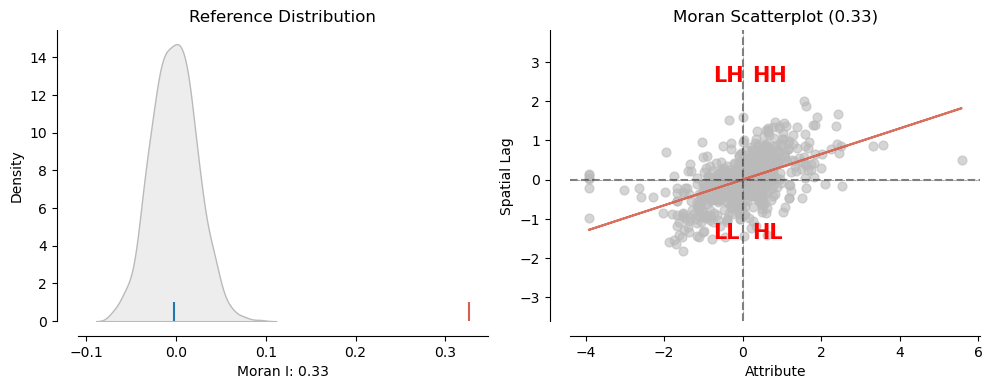

In [69]:
from splot.esda import plot_moran

y = melbourne_clean['Median_tot_hhd_inc_weekly'].values
moran = esda.moran.Moran(y, w)

y_standardized = (y - y.mean()) / y.std()
w_y = weights.spatial_lag.lag_spatial(w, y_standardized)

fig, ax = plot_moran(moran, aspect_equal=True)

scatter_ax = ax[1]

scatter_ax.axhline(y=0, color='gray', linestyle='--', linewidth=0.5)
scatter_ax.axvline(x=0, color='gray', linestyle='--', linewidth=0.5)

scatter_ax.text(0.25, 2.5, "HH", fontsize=15, c="red", fontweight='bold')
scatter_ax.text(0.25, -1.5, "HL", fontsize=15, c="red", fontweight='bold')
scatter_ax.text(-0.75, 2.5, "LH", fontsize=15, c="red", fontweight='bold')
scatter_ax.text(-0.75, -1.5, "LL", fontsize=15, c="red", fontweight='bold')

plt.tight_layout()
plt.show()

For example, Cape Schanck is in HH, which means the suburb's own household income is above the average level of Greater Melbourne, and the average income of its surrounding suburbs is also above the average level.

  HH (High-High): 222
  LH (Low-High): 78
  LL (Low-Low): 193
  HL (High-Low): 84


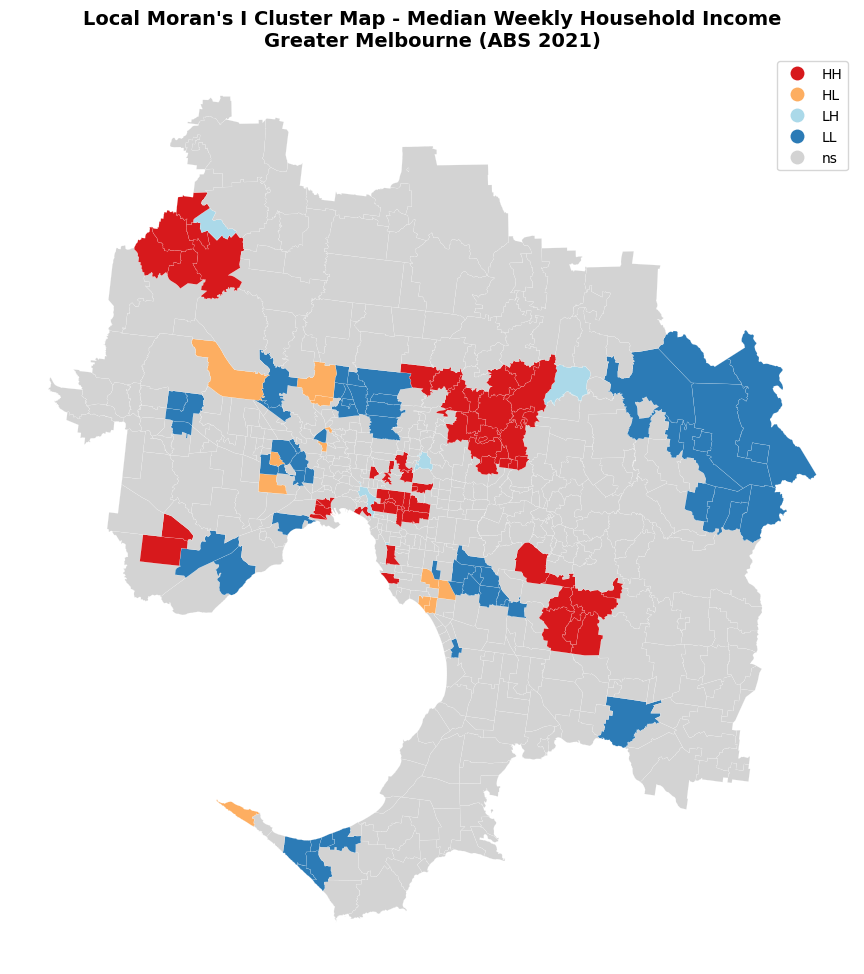

In [73]:
lisa = esda.moran.Moran_Local(y, w)

from collections import Counter
q_counts = Counter(lisa.q)
print(f"  HH (High-High): {q_counts.get(1, 0)}")
print(f"  LH (Low-High): {q_counts.get(2, 0)}")
print(f"  LL (Low-Low): {q_counts.get(3, 0)}")
print(f"  HL (High-Low): {q_counts.get(4, 0)}")

fig, ax = plt.subplots(1, 1, figsize=(12, 10))
lisa_cluster(lisa, melbourne_clean, p=0.05, ax=ax)


ax.set_title('Local Moran\'s I Cluster Map - Median Weekly Household Income\nGreater Melbourne (ABS 2021)', 
             fontsize=14, fontweight='bold')

ax.set_axis_off()

plt.tight_layout()
plt.show()